# Trabajo practico especial - Analisis de enfermedad renal cronica

# 1. Preparación del entorno y carga de datos


Lo principal y más importante para explorar los datos es primeramente, obtener el dataset y su metadata.

## 1.1. Librerías

In [32]:
from wget import download
from os import path, makedirs
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## 1.2. Carga del dataset

In [33]:
makedirs("resources", exist_ok=True)

archivo_metadata = "resources/metadata.docx"
archivo_dataset = "resources/CKD_NHANES_2021_2023.csv"

if not path.exists(archivo_metadata):
    download(
        "https://drive.google.com/uc?export=download&id=1dJRgbPz48x1vbX0E3_4OZ1u4Q33hyQCI",
        archivo_metadata
    )
else:
    print("el archivo de la metadata ya existe")

if not path.exists(archivo_dataset):
    download(
        "https://drive.google.com/uc?export=download&id=1p5GjM2xPLSIm44ET6n5A1NDi3eOf6ghU",
        archivo_dataset
    )

else:
    print("el dataset ya existe")

el archivo de la metadata ya existe
el dataset ya existe


In [34]:
# Instanciamos el dataset en un DataFrame de pandas
df = pd.read_csv(archivo_dataset)

# Creamos la copia que usaremos para explorar y limpiar los datos.
df_limpio = df.copy()

# 2. Análisis exploratorio y preparación de los datos

## 2.1. Primera inspección de los datos

In [35]:
# Permite ver todas las columnas del DataFrame sin truncar la salida
pd.set_option("display.max_columns", None)
df.head()


,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


## 2.2. Identificación de participantes

Antes de explorar las variables, contamos los valores repetidos de `participant_id`. Si no hay identificadores repetidos, excluimos esta columna de `df_limpio` porque identifica participantes y no representa una medición. Si hay repetidos, la conservamos para revisarlos. El DataFrame original `df` mantiene todas sus columnas.


In [36]:

long_df = len(df)
id_distintos = df["participant_id"].nunique()

print("Cantidad de filas:", long_df)
print("Identificadores distintos:", id_distintos)


if id_distintos  == long_df:
    df_limpio = df_limpio.drop(columns=["participant_id"])
    print("Todos los identificadores son únicos; se excluyen de df_limpio.")
else:
    print("Hay identificadores repetidos; se conserva participant_id para revisarlos.")


Cantidad de filas: 11933
Identificadores distintos: 11933
Todos los identificadores son únicos; se excluyen de df_limpio.


## 2.3. Inspección de tipos y variables

Vemos que hay variables que son de tipo float64 y terminan desaprovechandose o se podria trabajar de mejor manera si reconvertimos el tipo de la variable.
En la metadata se observa una advertencia sobre valores positivos diminutos que representan cero, reemplacemos esos valores antes de realizar las conversiones a las columnas

In [57]:
# Conocer un poco mas las variables
df_limpio.describe(include="all")

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
count,11933.0,11933,11933,7794.0,9.892000e+03,8471.000000,8754.000000,8499.000000,7517.000000,7517.000000,6326.000000,6326.000000,6366.000000,6322.000000,6325.000000,6362.000000,6329.000000,8154.000000,8153.000000,8153.000000,11740.0,1081,2274,8121,3243.0,6326.000000,11933,6326.0
unique,<NA>,2,6,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,2,2,2,<NA>,NaN,8,<NA>
top,<NA>,Female,Non-Hispanic White,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,False,False,False,<NA>,NaN,Unknown,<NA>
freq,<NA>,6358,6217,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,737,1389,4878,<NA>,NaN,5607,<NA>
mean,38.317858,NaN,NaN,3.804978,2.708174e+00,27.246665,70.549037,159.664549,119.288546,72.748038,0.872828,14.659817,4.099246,3.608573,24.449012,9.428969,5.133670,133.258646,35.567928,33.355533,1.934497,NaN,NaN,NaN,2.3395,96.599750,NaN,0.432185
std,25.60199,NaN,NaN,1.15375,1.670119e+00,8.137781,30.389021,19.864943,18.561052,11.895572,0.385498,5.754035,0.355161,0.569378,2.411849,0.381800,1.407571,90.676053,175.582217,251.094041,0.358726,NaN,NaN,NaN,0.900889,24.633731,NaN,0.495419
min,0.0,NaN,NaN,1.0,5.397605e-79,11.100000,2.700000,79.100000,61.000000,33.000000,0.330000,4.000000,2.200000,1.600000,15.000000,7.500000,1.100000,4.000000,0.210000,0.080000,1.0,NaN,NaN,NaN,1.0,3.510000,NaN,0.0
25%,13.0,NaN,NaN,3.0,1.180000e+00,21.600000,54.200000,154.400000,106.000000,64.000000,0.700000,11.000000,3.900000,3.200000,23.000000,9.200000,4.100000,65.000000,5.770000,5.420000,2.0,NaN,NaN,NaN,1.0,80.502500,NaN,0.0
50%,37.0,NaN,NaN,4.0,2.500000e+00,26.400000,71.700000,163.600000,117.000000,72.000000,0.830000,14.000000,4.100000,3.600000,24.000000,9.400000,5.000000,117.000000,9.620000,8.270000,2.0,NaN,NaN,NaN,3.0,97.030000,NaN,0.0
75%,62.0,NaN,NaN,5.0,4.500000e+00,31.700000,89.100000,172.100000,130.000000,80.000000,0.980000,17.000000,4.300000,3.900000,26.000000,9.700000,6.000000,181.000000,17.830000,15.330000,2.0,NaN,NaN,NaN,3.0,112.660000,NaN,1.0


## 2.4. Corrección y conversión de variables

El archivo metatada.docx menciona que el DataSet cuenta con un error por la conversion del archivo, tienen valores muy cercanos a 0, que deberian ser 0, pero estan mal convertidos. 

In [38]:
# Corregir las edades positivas extremadamente cercanas a cero.
edades_cercanas_a_cero = (df_limpio["age"] > 0) & (df_limpio["age"] < 1e-10)
df_limpio.loc[edades_cercanas_a_cero, "age"] = 0

# Convertir los códigos y las edades a enteros, conservando nulos.
for columna in ["age", "education_level", "diabetes_diagnosed", "current_smoker"]:
    df_limpio[columna] = df_limpio[columna].astype("Int64")

# Convertir las respuestas sí/no a booleanos.
for columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
    df_limpio[columna] = df_limpio[columna].replace({
        1: True,
        2: False,
        7: pd.NA,
        9: pd.NA
    }).astype("boolean")

df_limpio.dtypes

age                           Int64
gender                          str
ethnicity                       str
education_level               Int64
poverty_income_ratio        float64
bmi                         float64
weight_kg                   float64
height_cm                   float64
bp_systolic                 float64
bp_diastolic                float64
serum_creatinine            float64
blood_urea_nitrogen         float64
albumin_serum               float64
phosphorus                  float64
bicarbonate                 float64
calcium                     float64
uric_acid                   float64
urine_creatinine            float64
urine_albumin               float64
albumin_creatinine_ratio    float64
diabetes_diagnosed            Int64
insulin_use                 boolean
diabetes_pills              boolean
ever_smoked                 boolean
current_smoker                Int64
egfr                        float64
ckd_stage                       str
ckd_present                 

In [39]:
df_limpio.head()

,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,43,Male,Non-Hispanic Asian,5,5.00,27.0,86.9,179.5,135.0,98.0,0.80,11.0,4.3,3.7,24.0,9.6,5.1,136.0,23.12,17.00,2,<NA>,<NA>,True,3,112.61,No CKD,0
1,66,Male,Non-Hispanic White,5,5.00,33.5,101.8,174.2,121.0,84.0,0.79,24.0,3.9,3.2,25.0,9.4,8.5,64.0,4.25,6.64,2,<NA>,<NA>,True,3,97.98,No CKD,0
2,44,Female,Other Hispanic,3,1.41,29.7,69.4,152.9,111.0,79.0,0.64,10.0,3.7,3.8,25.0,9.4,4.4,157.0,12.43,7.92,1,False,True,False,<NA>,111.69,No CKD,0
3,5,Female,Other/Multiracial,<NA>,1.53,23.8,34.3,120.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,208.0,16.12,7.75,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1
4,2,Male,Non-Hispanic White,<NA>,3.60,NaN,13.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,<NA>,<NA>,<NA>,<NA>,NaN,Unknown,1


## 2.5. Tratamiento de la clasificación renal desconocida

Sabemos que cuando ckd_stage = Unknown -> ckd_present = 1; y eso no esta del todo bien, conviene dejar ese caso expresado como ckd_present = pd.NA por el momento


In [40]:
df_limpio["ckd_present"] = df_limpio["ckd_present"].astype("Int64")

df_limpio.loc[
    df_limpio["ckd_stage"] == "Unknown",
    "ckd_present"
] = pd.NA


## 2.6. Resumen de variables

El porcentaje de nulos corresponde al DataFrame limpio (`df_limpio`). El identificador se revisa al inicio de la exploración y se excluye de esta tabla.

| Variable | Tipo computacional antes | Tipo computacional después | Porcentaje de nulos |
|---|---|---|---:|
| insulin_use | float64 | boolean | 90.94% |
| diabetes_pills | float64 | boolean | 80.94% |
| current_smoker | float64 | Int64 | 72.82% |
| phosphorus | float64 | float64 | 47.02% |
| bicarbonate | float64 | float64 | 47.00% |
| serum_creatinine | float64 | float64 | 46.99% |
| blood_urea_nitrogen | float64 | float64 | 46.99% |
| egfr | float64 | float64 | 46.99% |
| ckd_present | int64 | Int64 | 46.99% |
| uric_acid | float64 | float64 | 46.96% |
| calcium | float64 | float64 | 46.69% |
| albumin_serum | float64 | float64 | 46.65% |
| bp_systolic | float64 | float64 | 37.01% |
| bp_diastolic | float64 | float64 | 37.01% |
| education_level | float64 | Int64 | 34.69% |
| ever_smoked | float64 | boolean | 31.95% |
| urine_albumin | float64 | float64 | 31.68% |
| albumin_creatinine_ratio | float64 | float64 | 31.68% |
| urine_creatinine | float64 | float64 | 31.67% |
| bmi | float64 | float64 | 29.01% |
| height_cm | float64 | float64 | 28.78% |
| weight_kg | float64 | float64 | 26.64% |
| poverty_income_ratio | float64 | float64 | 17.10% |
| diabetes_diagnosed | float64 | Int64 | 1.62% |
| age | float64 | Int64 | 0.00% |
| gender | str | str | 0.00% |
| ethnicity | str | str | 0.00% |
| ckd_stage | str | str | 0.00% |


In [41]:
# Codigo para sacar porcentajes de nulos por columna
porcentaje_nulos = df_limpio.isna().mean().mul(100)

porcentaje_nulos.sort_values(ascending=False).round(2)


insulin_use                 90.94
diabetes_pills              80.94
current_smoker              72.82
phosphorus                  47.02
bicarbonate                 47.00
blood_urea_nitrogen         46.99
egfr                        46.99
ckd_present                 46.99
serum_creatinine            46.99
uric_acid                   46.96
calcium                     46.69
albumin_serum               46.65
bp_systolic                 37.01
bp_diastolic                37.01
education_level             34.69
ever_smoked                 31.95
albumin_creatinine_ratio    31.68
urine_albumin               31.68
urine_creatinine            31.67
bmi                         29.01
height_cm                   28.78
weight_kg                   26.64
poverty_income_ratio        17.10
diabetes_diagnosed           1.62
gender                       0.00
age                          0.00
ethnicity                    0.00
ckd_stage                    0.00
dtype: float64

## 2.7. Frecuencias y distribuciones de las variables

Trabajamos con `df_limpio`, sin modificar sus valores. Distinguimos las variables por su significado, no solamente por el tipo de dato que usa pandas:

- **Identificador:** `participant_id`. Al inicio de la exploración se comprueba si hay valores repetidos. Si no hay repetidos, se retira de `df_limpio`; no se analiza como una variable cuantitativa.
- **Cuantitativa discreta:** `age`, registrada en años enteros.
- **Cuantitativas continuas:** medidas corporales, presiones, análisis de laboratorio, `poverty_income_ratio` y `egfr`.
- **Categóricas nominales:** `gender`, `ethnicity`, `diabetes_diagnosed` y las respuestas binarias `insulin_use`, `diabetes_pills`, `ever_smoked` y `ckd_present`.
- **Categóricas ordinales:** `education_level`, `current_smoker` y las etapas conocidas de `ckd_stage`. Los códigos 7/9 y `Unknown` no forman parte de ese orden.

Los porcentajes de frecuencias usan como denominador **todas las filas del archivo**, incluyendo las que no tienen respuesta. Mostramos por separado `Sin dato`, las respuestas 7/9 y `Unknown`. Un faltante en una pregunta condicional, como uso de insulina o tabaquismo actual, no equivale a una respuesta negativa.

Estas frecuencias describen el archivo: no son estimaciones ponderadas de la población de Estados Unidos.


In [42]:
import matplotlib.pyplot as plt
from IPython.display import display

variables_numericas = [
    "age", "poverty_income_ratio", "bmi", "weight_kg", "height_cm",
    "bp_systolic", "bp_diastolic", "serum_creatinine", "blood_urea_nitrogen",
    "albumin_serum", "phosphorus", "bicarbonate", "calcium", "uric_acid",
    "urine_creatinine", "urine_albumin", "albumin_creatinine_ratio", "egfr"
]

# Las etiquetas respetan el diccionario de variables de la metadata.
etiquetas_categorias = {
    "gender": {"Female": "Femenino", "Male": "Masculino"},
    "ethnicity": {
        "Mexican American": "Mexicano estadounidense",
        "Other Hispanic": "Otro hispano",
        "Non-Hispanic White": "Blanco no hispano",
        "Non-Hispanic Black": "Negro no hispano",
        "Non-Hispanic Asian": "Asiático no hispano",
        "Other/Multiracial": "Otro / multirracial"
    },
    "education_level": {
        1: "Menos de noveno grado",
        2: "Noveno a undécimo grado",
        3: "Secundaria completa / equivalente",
        4: "Superior incompleto / terciario corto",
        5: "Universitario o superior",
        7: "Se negó a responder (7)",
        9: "No sabe (9)"
    },
    "diabetes_diagnosed": {
        1: "Sí", 2: "No", 3: "Diagnóstico límite",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "insulin_use": {True: "Sí", False: "No"},
    "diabetes_pills": {True: "Sí", False: "No"},
    "ever_smoked": {True: "Sí", False: "No"},
    "current_smoker": {
        1: "Todos los días", 2: "Algunos días", 3: "Actualmente no fuma",
        7: "Se negó a responder (7)", 9: "No sabe (9)"
    },
    "ckd_stage": {
        "No CKD": "No CKD",
        "Stage 1 (Kidney Damage)": "Etapa 1",
        "Stage 2 (Mildly Decreased)": "Etapa 2",
        "Stage 3a (Mild-Moderate)": "Etapa 3a",
        "Stage 3b (Moderate-Severe)": "Etapa 3b",
        "Stage 4 (Severely Decreased)": "Etapa 4",
        "Stage 5 (Kidney Failure)": "Etapa 5",
        "Unknown": "Etapa desconocida"
    },
    "ckd_present": {0: "Sin CKD según el archivo", 1: "Con CKD según el archivo"}
}


## 2.8. Frecuencias de las variables categóricas

Cada tabla muestra la cantidad de personas y su porcentaje sobre el total de filas. Las barras conservan el orden de las categorías del diccionario y muestran también las categorías sin observaciones.

Las conversiones previas unificaron los códigos 7/9 y los nulos de las tres variables booleanas como `pd.NA`. Para no perder esa distinción en este análisis, recuperamos las respuestas originales de esas tres columnas desde `df`, solo para construir sus tablas de frecuencias. No cambiamos `df_limpio`.


gender


,Frecuencia,Porcentaje del total
gender,,
Femenino,6358,53.28
Masculino,5575,46.72
Sin dato,0,0.00


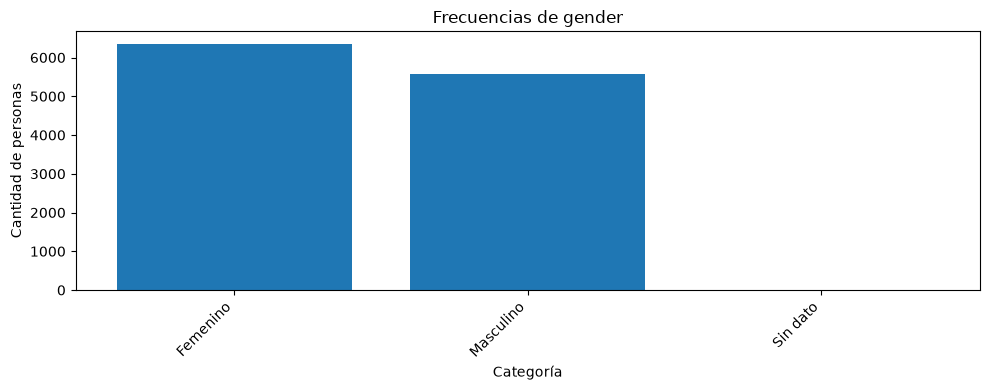

ethnicity


,Frecuencia,Porcentaje del total
ethnicity,,
Mexicano estadounidense,1117,9.36
Otro hispano,1373,11.51
Blanco no hispano,6217,52.10
Negro no hispano,1597,13.38
Asiático no hispano,681,5.71
Otro / multirracial,948,7.94
Sin dato,0,0.00


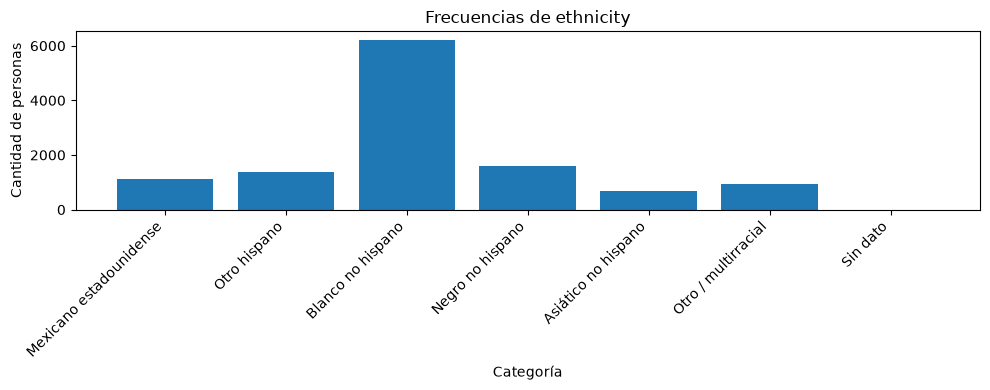

education_level


,Frecuencia,Porcentaje del total
education_level,,
Menos de noveno grado,373,3.13
Noveno a undécimo grado,666,5.58
Secundaria completa / equivalente,1749,14.66
Superior incompleto / terciario corto,2370,19.86
Universitario o superior,2625,22.00
Se negó a responder (7),0,0.00
No sabe (9),11,0.09
Sin dato,4139,34.69


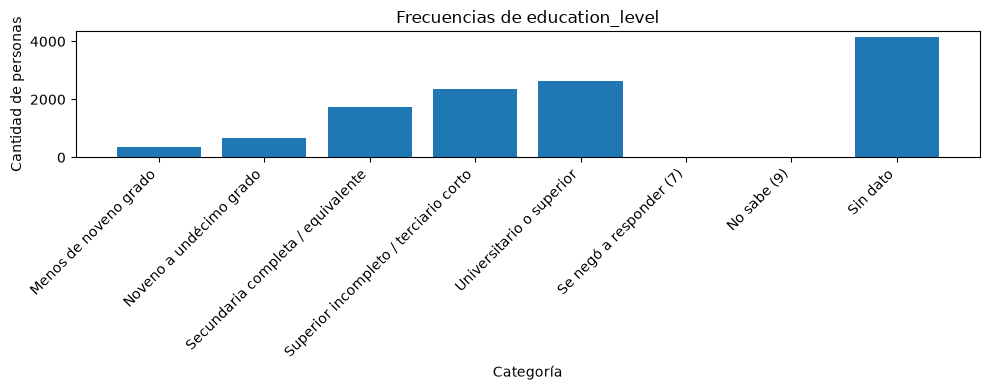

diabetes_diagnosed


,Frecuencia,Porcentaje del total
diabetes_diagnosed,,
Sí,1081,9.06
No,10371,86.91
Diagnóstico límite,284,2.38
Se negó a responder (7),0,0.00
No sabe (9),4,0.03
Sin dato,193,1.62


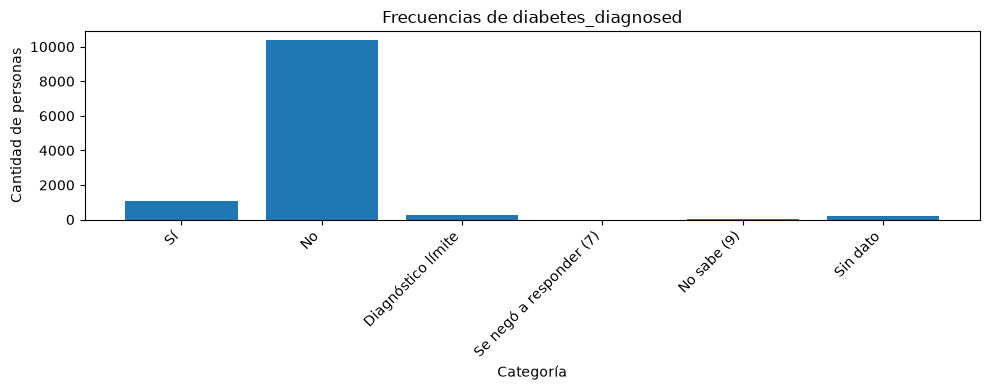

insulin_use


,Frecuencia,Porcentaje del total
insulin_use,,
Sí,344,2.88
No,737,6.18
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,10852,90.94


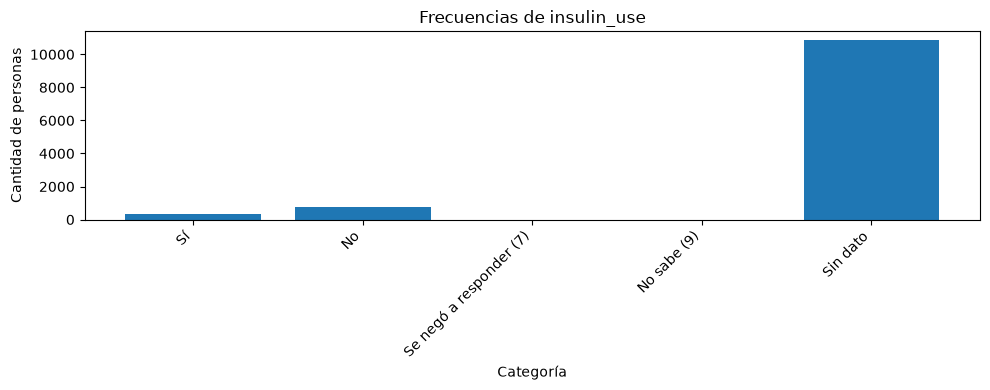

diabetes_pills


,Frecuencia,Porcentaje del total
diabetes_pills,,
Sí,885,7.42
No,1389,11.64
Se negó a responder (7),0,0.00
No sabe (9),7,0.06
Sin dato,9652,80.88


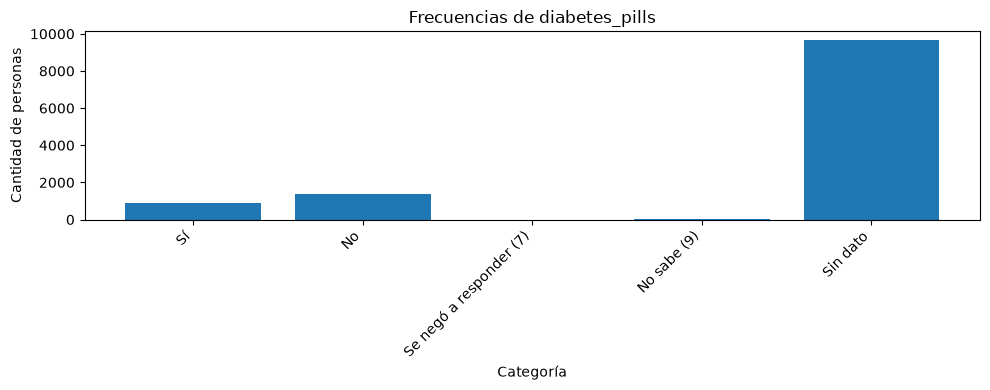

ever_smoked


,Frecuencia,Porcentaje del total
ever_smoked,,
Sí,3243,27.18
No,4878,40.88
Se negó a responder (7),7,0.06
No sabe (9),7,0.06
Sin dato,3798,31.83


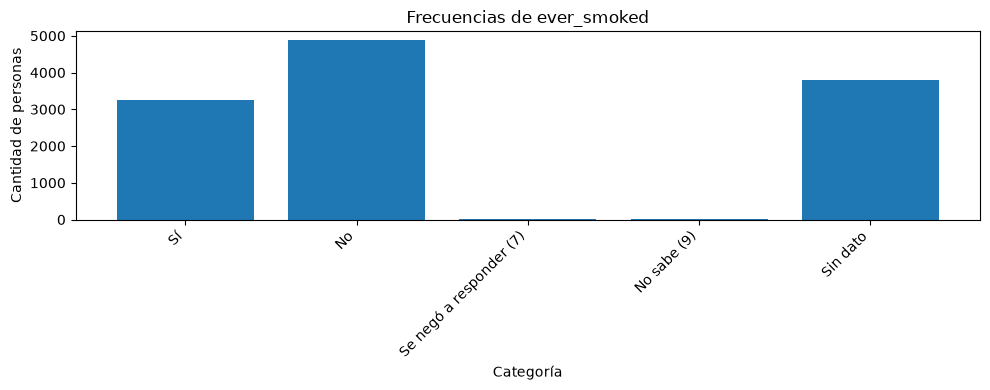

current_smoker


,Frecuencia,Porcentaje del total
current_smoker,,
Todos los días,952,7.98
Algunos días,238,1.99
Actualmente no fuma,2053,17.20
Se negó a responder (7),0,0.00
No sabe (9),0,0.00
Sin dato,8690,72.82


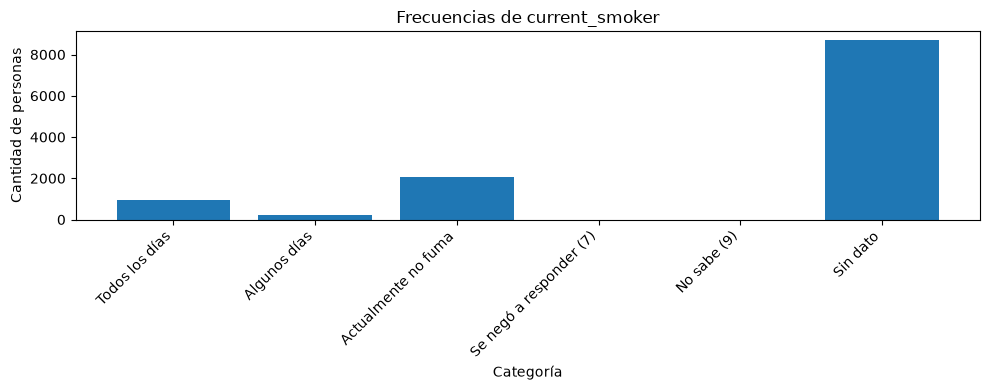

ckd_stage


,Frecuencia,Porcentaje del total
ckd_stage,,
No CKD,3592,30.10
Etapa 1,382,3.20
Etapa 2,1875,15.71
Etapa 3a,341,2.86
Etapa 3b,97,0.81
Etapa 4,28,0.23
Etapa 5,11,0.09
Etapa desconocida,5607,46.99
Sin dato,0,0.00


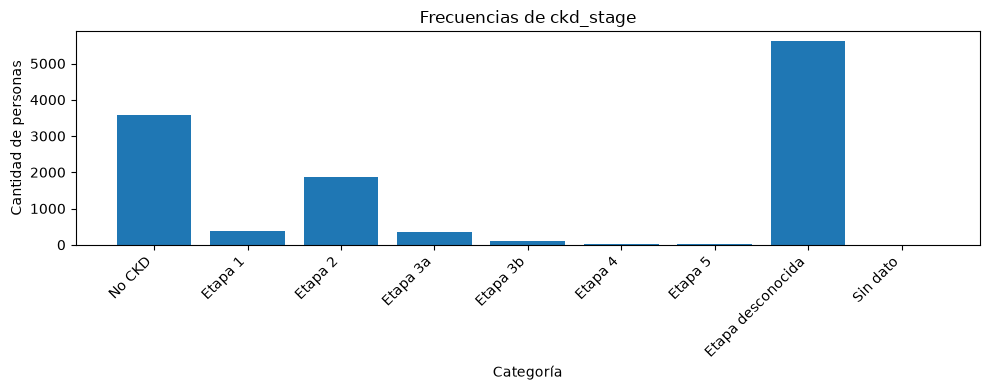

ckd_present


,Frecuencia,Porcentaje del total
ckd_present,,
Sin CKD según el archivo,3592,30.10
Con CKD según el archivo,2734,22.91
Sin dato,5607,46.99


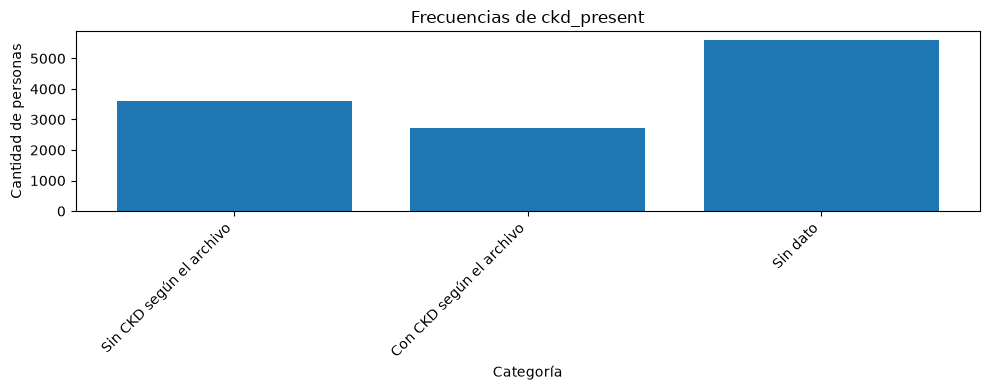

In [43]:
frecuencias_categoricas = {}

for columna, etiquetas in etiquetas_categorias.items():
    # Recuperamos los códigos de no respuesta que la conversión booleana unificó.
    if columna in ["insulin_use", "diabetes_pills", "ever_smoked"]:
        serie = df[columna].replace({
            1: "Sí", 2: "No",
            7: "Se negó a responder (7)", 9: "No sabe (9)"
        }).fillna("Sin dato")
        orden = ["Sí", "No", "Se negó a responder (7)", "No sabe (9)", "Sin dato"]
    else:
        serie = df_limpio[columna].astype("object").replace(etiquetas).fillna("Sin dato")
        orden = list(etiquetas.values()) + ["Sin dato"]

    # Conservamos también cualquier categoría que no figure en la metadata.
    serie = serie.astype(str)
    frecuencias = serie.value_counts()
    categorias_adicionales = [valor for valor in frecuencias.index if valor not in orden]
    frecuencias = frecuencias.reindex(orden + categorias_adicionales, fill_value=0)
    tabla = pd.DataFrame({
        "Frecuencia": frecuencias,
        "Porcentaje del total": (frecuencias / len(df_limpio) * 100).round(2)
    })
    frecuencias_categoricas[columna] = tabla
    print(columna)
    display(tabla)

    plt.figure(figsize=(10, 4))
    plt.bar(tabla.index, tabla["Frecuencia"])
    plt.title("Frecuencias de " + columna)
    plt.xlabel("Categoría")
    plt.ylabel("Cantidad de personas")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## 2.9. Resumen de las variables cuantitativas

`count` indica cuántos valores observados intervienen en cada resumen. Media, desvío estándar, mínimo, cuartiles, mediana y máximo se calculan sin los nulos; no se imputan valores. Los códigos de categorías y el identificador quedan fuera de estos cálculos.

Las unidades se consultan en la metadata: edad en años; peso en kg; altura en cm; BMI en kg/m²; presiones en mmHg; creatinina sérica, nitrógeno ureico, fósforo, calcio, ácido úrico y creatinina urinaria en mg/dL; albúmina sérica en g/dL; bicarbonato en mmol/L; albúmina urinaria en µg/mL; ACR en mg/g; eGFR en mL/min/1,73 m². La razón ingreso/pobreza no tiene unidad.


In [44]:
resumen_numericas = df_limpio[variables_numericas].describe().T
resumen_numericas["nulos"] = df_limpio[variables_numericas].isna().sum()
resumen_numericas["porcentaje_nulos"] = (
    df_limpio[variables_numericas].isna().mean() * 100
)
resumen_numericas.round(2)


,count,mean,std,min,25%,50%,75%,max,nulos,porcentaje_nulos
age,11933.0,38.317858,25.60199,0.0,13.0,37.0,62.0,80.0,0,0.00
poverty_income_ratio,9892.0,2.708174,1.670119,0.0,1.18,2.5,4.5,5.0,2041,17.10
bmi,8471.0,27.246665,8.137781,11.1,21.6,26.4,31.7,74.8,3462,29.01
weight_kg,8754.0,70.549037,30.389021,2.7,54.2,71.7,89.1,248.2,3179,26.64
height_cm,8499.0,159.664549,19.864943,79.1,154.4,163.6,172.1,200.7,3434,28.78
bp_systolic,7517.0,119.288546,18.561052,61.0,106.0,117.0,130.0,232.0,4416,37.01
bp_diastolic,7517.0,72.748038,11.895572,33.0,64.0,72.0,80.0,142.0,4416,37.01
serum_creatinine,6326.0,0.872828,0.385498,0.33,0.7,0.83,0.98,15.17,5607,46.99
blood_urea_nitrogen,6326.0,14.659817,5.754035,4.0,11.0,14.0,17.0,74.0,5607,46.99
albumin_serum,6366.0,4.099246,0.355161,2.2,3.9,4.1,4.3,5.5,5567,46.65


## 2.10. Distribuciones de las variables cuantitativas

Los histogramas agrupan los valores observados en 30 intervalos. Los ejes son independientes: las alturas y los rangos no deben compararse directamente entre variables con distintas cantidades de datos o unidades. Los extremos se conservan.


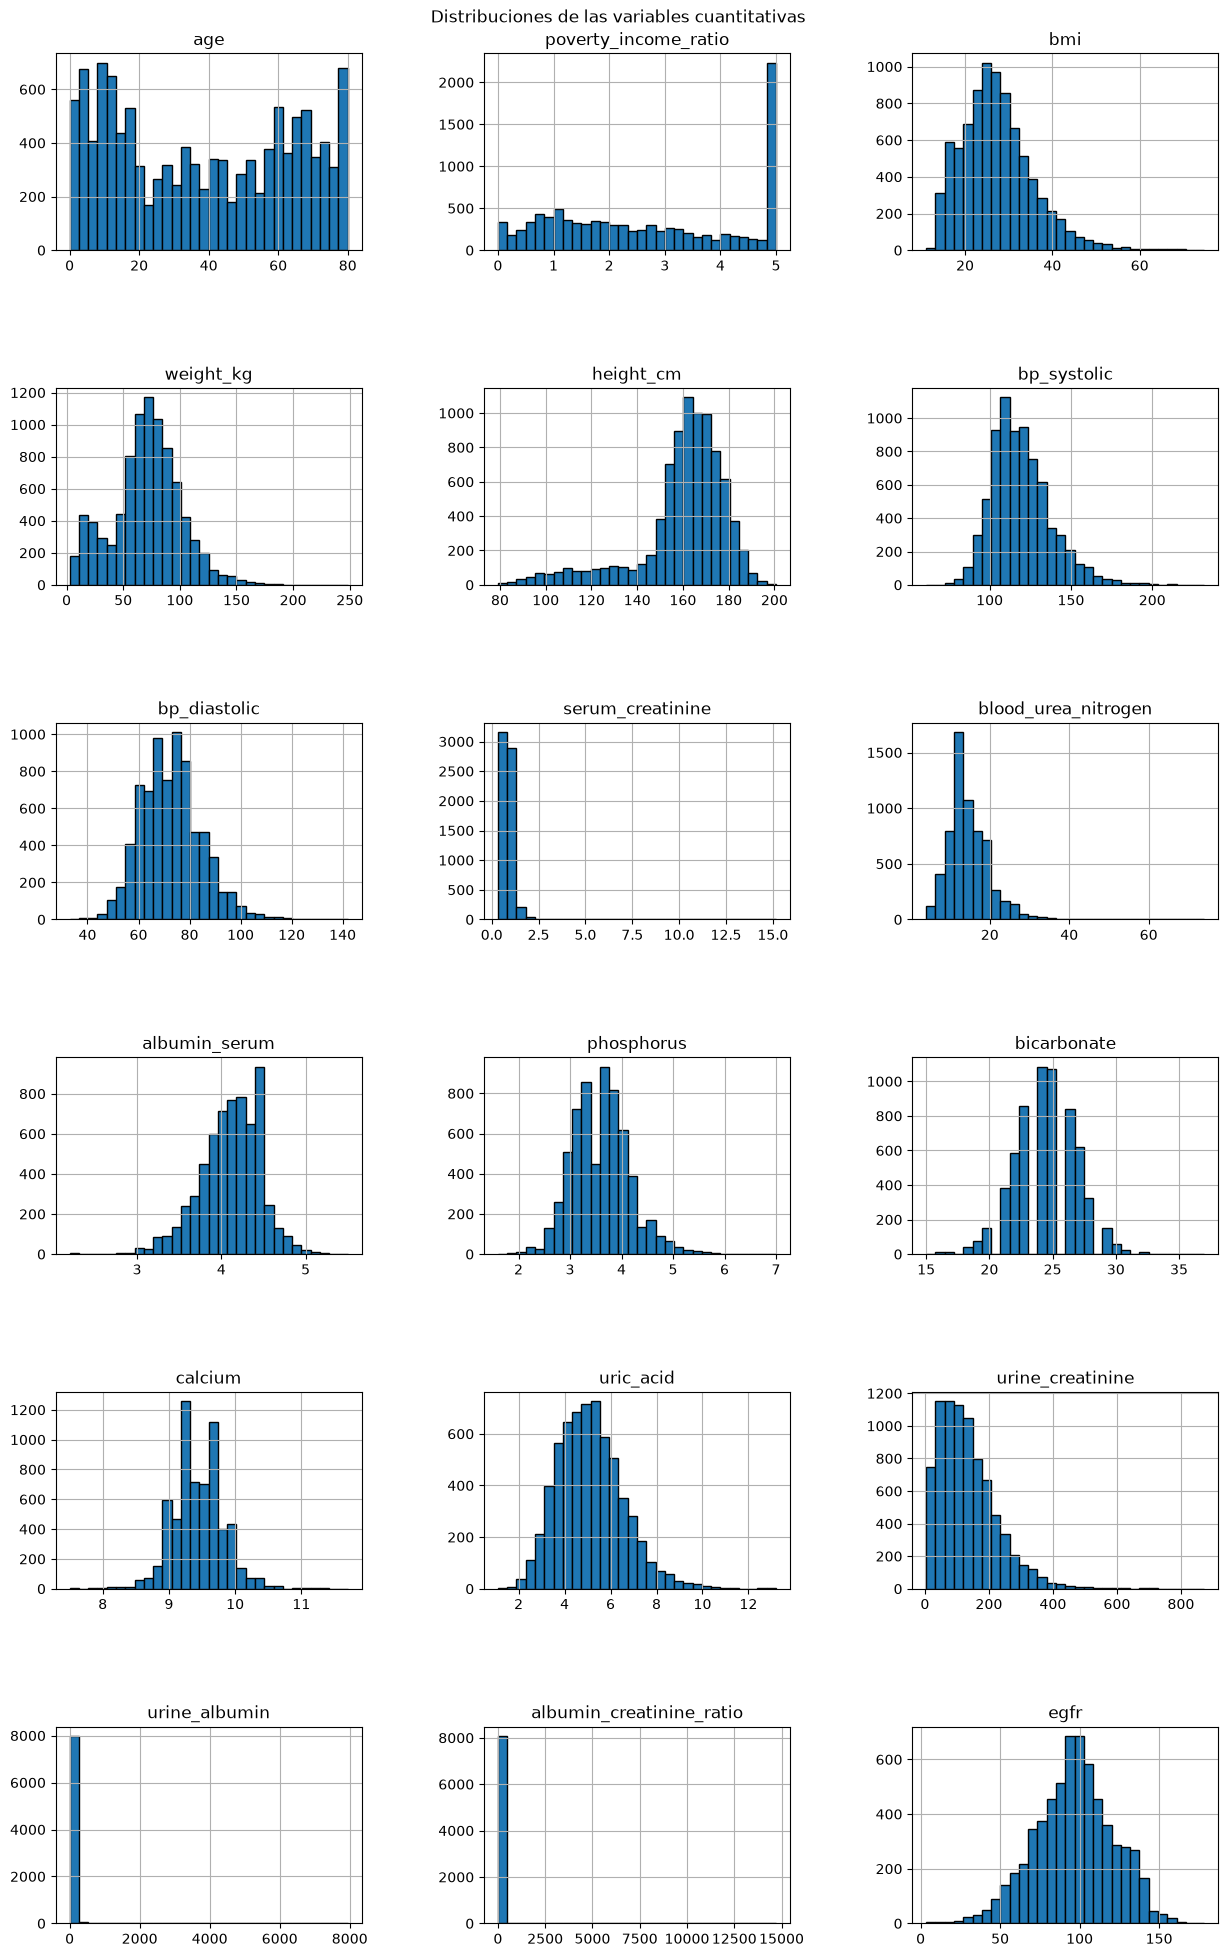

In [45]:
df_limpio[variables_numericas].hist(
    figsize=(15, 22), layout=(6, 3), bins=30, edgecolor="black"
)
plt.subplots_adjust(top=0.96, hspace=0.7, wspace=0.4)
plt.suptitle("Distribuciones de las variables cuantitativas")
plt.show()


## 2.11. Histogramas con escala ajustada

En los histogramas generales, los valores altos de `urine_albumin`, `albumin_creatinine_ratio` y `serum_creatinine` comprimen la zona donde se concentra la mayor parte de los datos. Para observar mejor sus distribuciones, agregamos histogramas con rangos acotados.

Estos gráficos muestran únicamente los valores dentro de los rangos indicados. Los valores que quedan fuera de esos rangos permanecen en el dataset; el ajuste solo cambia la visualización.


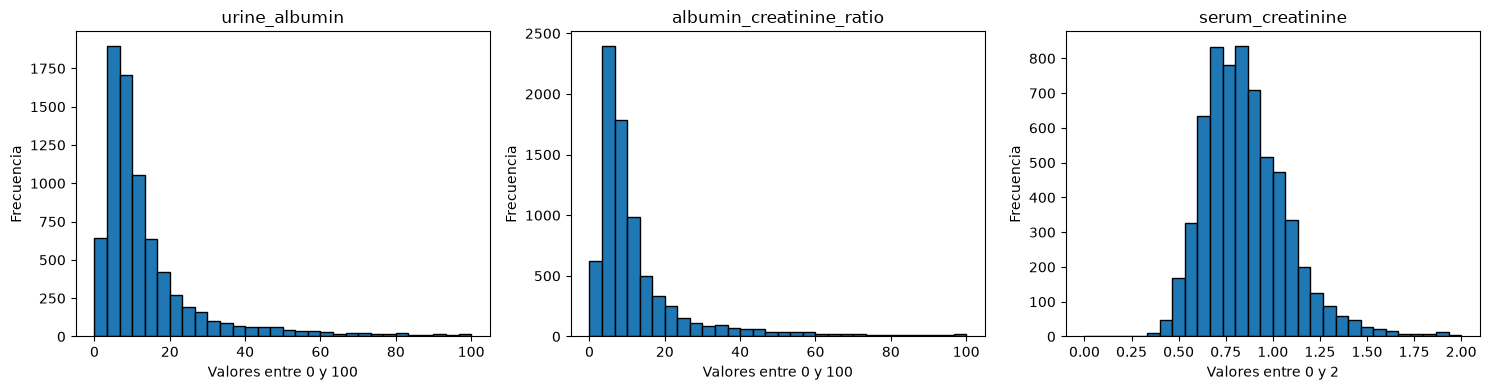

In [46]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4))

for columna, limite, eje in zip(
    ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"],
    [100, 100, 2], ejes
):
    eje.hist(df_limpio[columna].dropna(), bins=30, range=(0, limite), edgecolor="black")
    eje.set_title(columna)
    eje.set_xlabel(f"Valores entre 0 y {limite}")
    eje.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## 2.12. Medianas, dispersión y valores extremos

Cada diagrama de caja usa su propia escala y omite los nulos. La línea central representa la mediana y la caja contiene el 50% central. Los puntos fuera de los bigotes son posibles valores extremos según la regla de 1,5 veces el rango intercuartílico; no son errores confirmados y no se eliminan.


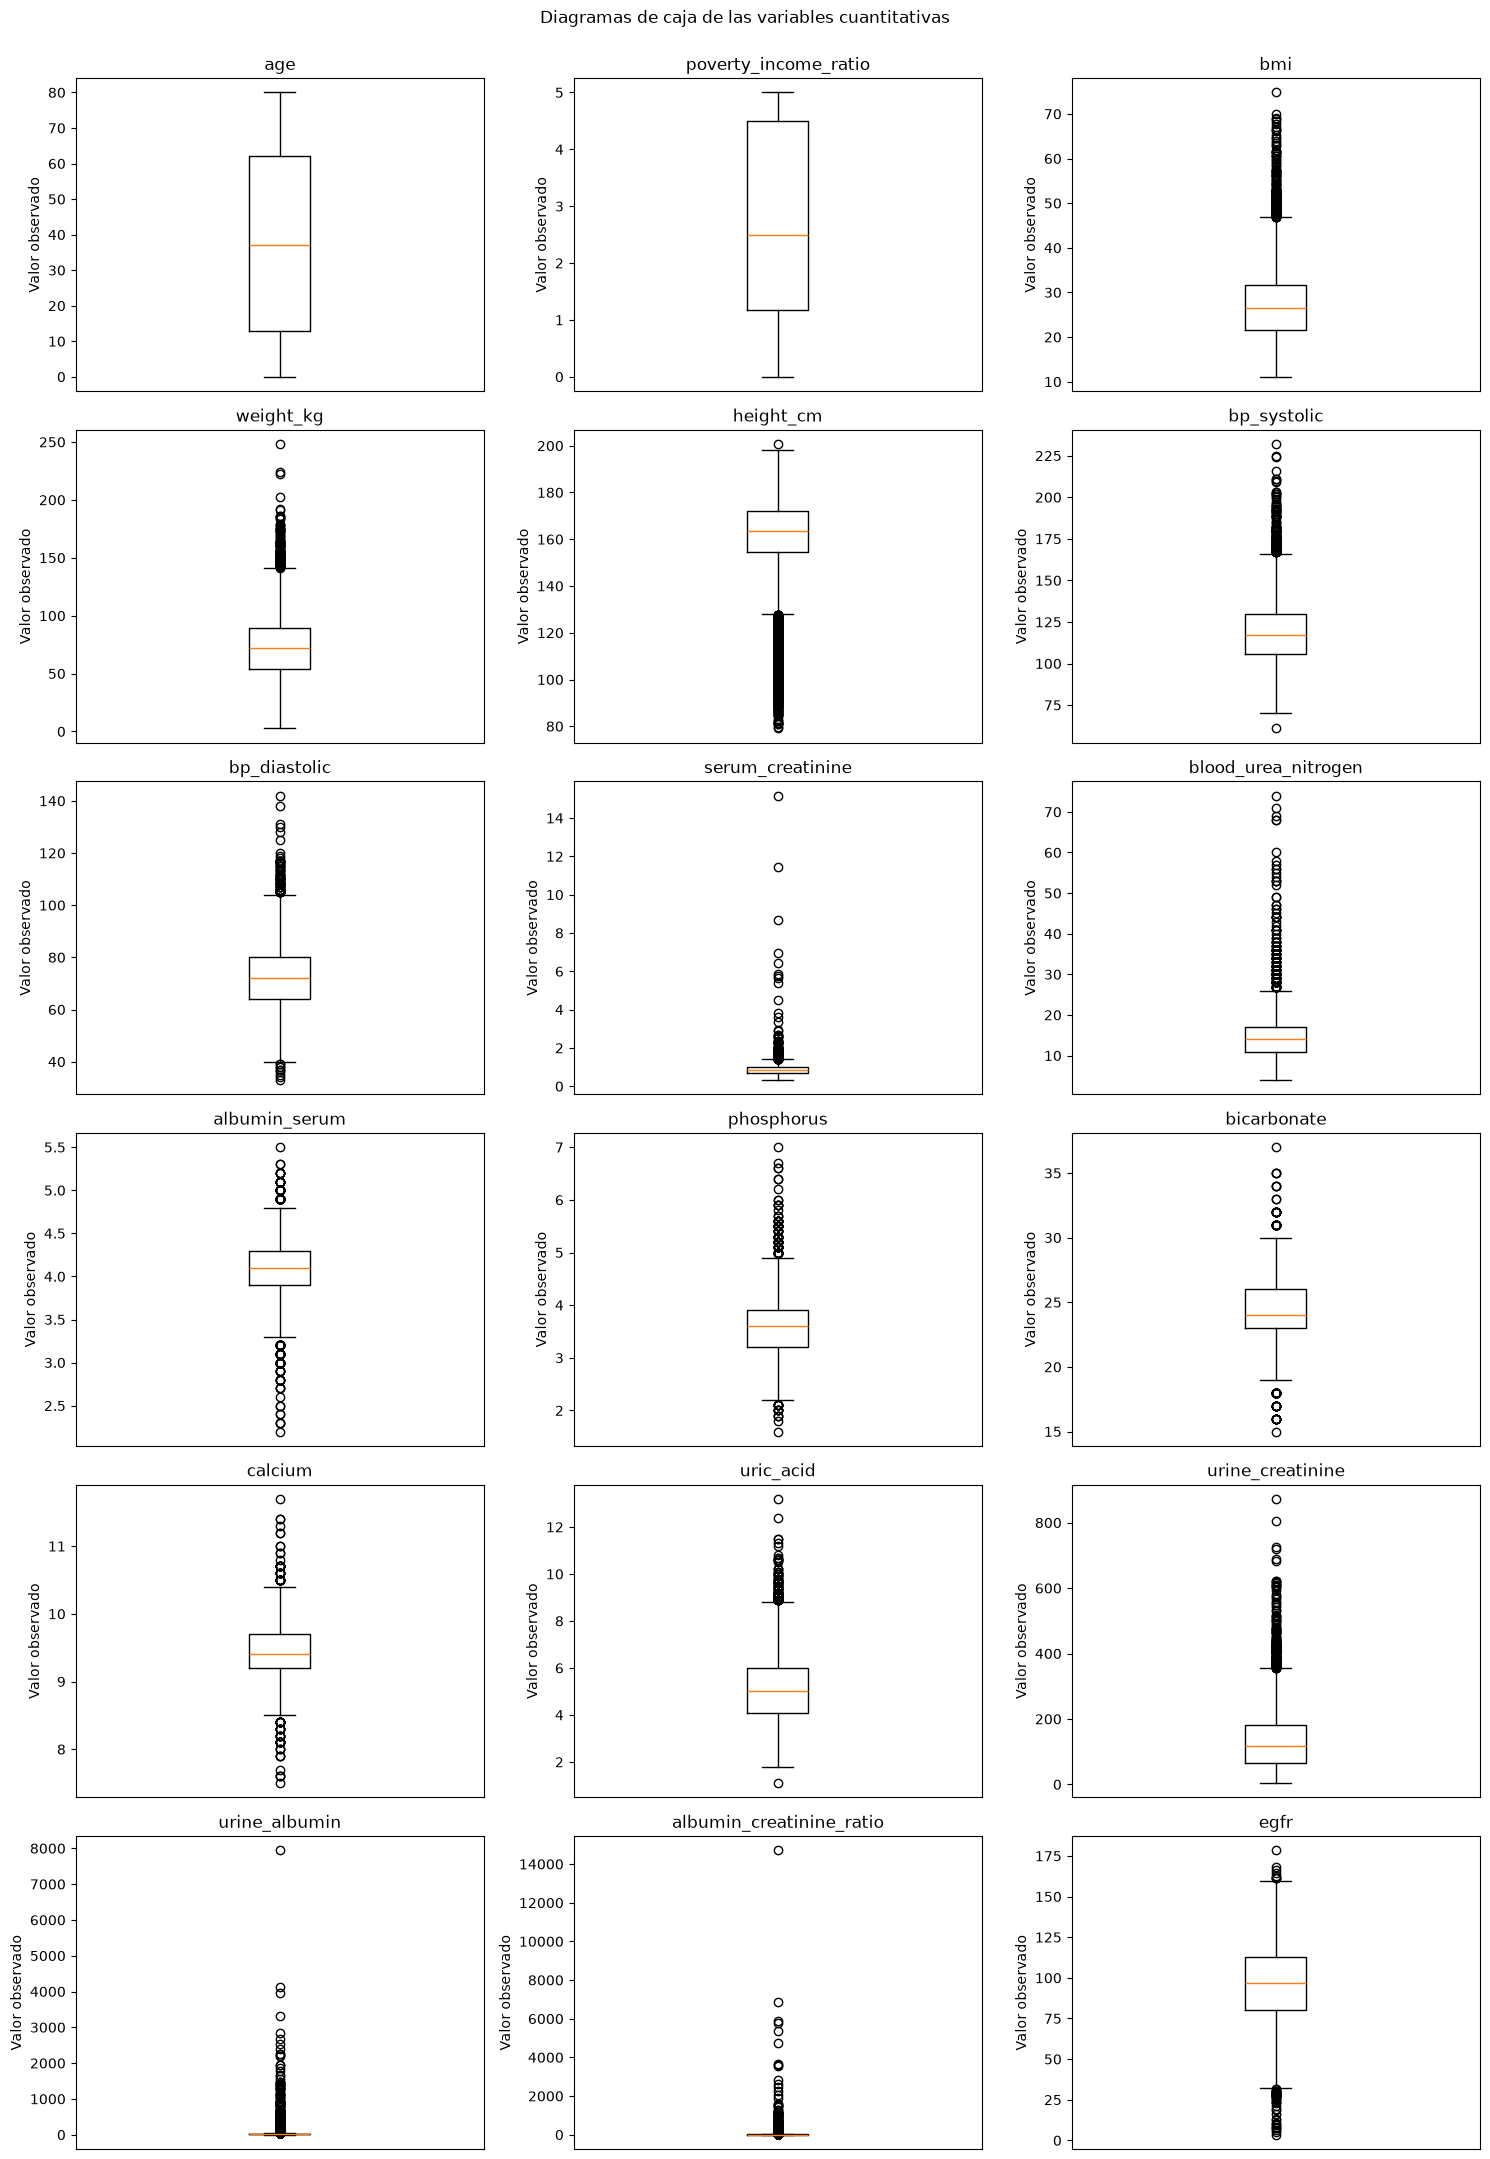

In [47]:
figura, ejes = plt.subplots(6, 3, figsize=(15, 22))

for columna, eje in zip(variables_numericas, ejes.flat):
    valores = df_limpio[columna].dropna().astype(float)
    eje.boxplot(valores)
    eje.set_title(columna)
    eje.set_xticks([])
    eje.set_ylabel("Valor observado")

figura.suptitle("Diagramas de caja de las variables cuantitativas")
figura.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


## 2.13. Filas que contienen los máximos seleccionados

Mostramos todas las filas que contienen el máximo de `urine_albumin`, `albumin_creatinine_ratio` o `serum_creatinine`. Si varias filas comparten un máximo, se muestran todas. Una fila que coincide en más de una variable aparece una sola vez.

Esta consulta permite revisar los registros completos. `df` y `df_limpio` conservan todas sus filas.


In [48]:
variables_maximos = ["urine_albumin", "albumin_creatinine_ratio", "serum_creatinine"]
filas_con_maximos = pd.Series(False, index=df_limpio.index)

for columna in variables_maximos:
    maximo = df_limpio[columna].max()
    print(f"Máximo de {columna}: {maximo}")
    filas_con_maximos = filas_con_maximos | (df_limpio[columna] == maximo).fillna(False)

print("Filas que contienen alguno de los máximos:", filas_con_maximos.sum())
display(df_limpio.loc[filas_con_maximos])


Máximo de urine_albumin: 7942.47
Máximo de albumin_creatinine_ratio: 14708.28
Máximo de serum_creatinine: 15.17
Filas que contienen alguno de los máximos: 1


,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,bp_diastolic,serum_creatinine,blood_urea_nitrogen,albumin_serum,phosphorus,bicarbonate,calcium,uric_acid,urine_creatinine,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
6251,50,Male,Non-Hispanic Asian,5,1.26,27.4,79.9,170.7,139.0,71.0,15.17,52.0,3.9,6.6,23.0,8.6,7.7,54.0,7942.47,14708.28,1,True,False,True,3,3.51,Stage 5 (Kidney Failure),1


# 3. Hipótesis y resolución

## 3.1. Hipótesis propia univariada

Hipotesis:En la población general examinada con función renal evaluable, la mediana de la relación albúmina-creatinina en orina (ACR) se mantiene significativamente por debajo del umbral clínico de daño renal 30 mg/g

Comenzamos tomando la variable sin nulos, y chequeando test de normalidad mediante shapiro-wilk

In [49]:
from scipy.stats import shapiro

acr = df_limpio["albumin_creatinine_ratio"].dropna()

stat, p = shapiro(acr)
print(f"Test de Shapiro-Wilk sobre ACR: Estadístico={stat:.3f}, p-valor={p:.3f}")



Test de Shapiro-Wilk sobre ACR: Estadístico=0.070, p-valor=0.000


/home/tomas/Proyectos/ciencia_datos/TpEspecial/.venv/lib/python3.14/site-packages/scipy/stats/_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8153.
  res = hypotest_fun_out(*samples, **kwds)


En este caso vemos que los datos no son normales, como habiamos detallado antes hay una gran prescencia de outliers

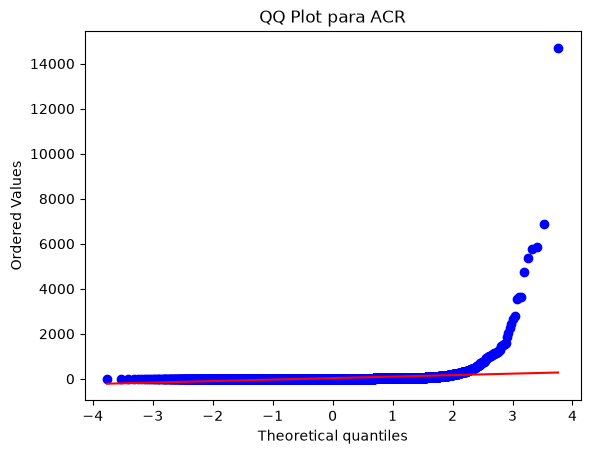

In [50]:
import matplotlib.pyplot as plt
import scipy.stats as stats

stats.probplot(acr, dist="norm", plot=plt)
plt.title("QQ Plot para ACR")
plt.show()

In [51]:
stat_wilcox, p_wilcox = stats.wilcoxon(acr - 30, alternative="less")

In [52]:
print(f"Mediana de ACR: {acr.median():.2f} mg/g | Media de ACR: {acr.mean():.2f} mg/g")
print(f"Test de Wilcoxon (mediana < 30): estadístico = {stat_wilcox:.2f}, p-valor = {p_wilcox:.4e}")

Mediana de ACR: 8.27 mg/g | Media de ACR: 33.36 mg/g
Test de Wilcoxon (mediana < 30): estadístico = 4790841.00, p-valor = 0.0000e+00


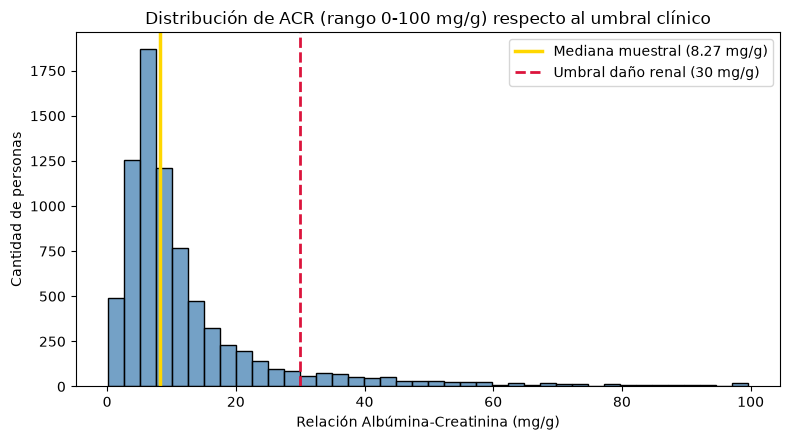

In [53]:
# 4. Visualización (Histograma acotado + líneas de referencia, estilo Práctico 5)
plt.figure(figsize=(8, 4.5))
sns.histplot(acr[acr <= 100], bins=40, color="steelblue", edgecolor="black")
plt.axvline(acr.median(), color="gold", linewidth=2.5, label=f"Mediana muestral ({acr.median():.2f} mg/g)")
plt.axvline(30, color="crimson", linestyle="--", linewidth=2, label="Umbral daño renal (30 mg/g)")
plt.title("Distribución de ACR (rango 0-100 mg/g) respecto al umbral clínico")
plt.xlabel("Relación Albúmina-Creatinina (mg/g)")
plt.ylabel("Cantidad de personas")
plt.legend()
plt.tight_layout()
plt.show()

Como vemos que el p-valor es muy menor a 0.05 podemos rechazar la H0, y confirma nuestra hipotesis.

## 3.2. Hipótesis propia bivariada

Hipotesis: La prevalencia de enfermedad renal crónica (ckd_present) no es independiente del diagnóstico de diabetes (diabetes_diagnosed), siendo significativamente superior en personas diagnosticadas con diabetes o prediabetes (diagnóstico límite). Elegimos la misma ya que nos interesa probar que la diabetes, es la principal causa de la ECR

H0: La presencia de ERC y el diagnóstico de diabetes son estadísticamente independientes.
H1: Existe asociación estadística entre el diagnóstico de diabetes y la presencia de ERC.

Para el test, analizamos que ambas variables son cualitataticas, codificadas. y como estamos chequeado independencia de 2 cualitativas debemos utilizar chi cuadrado mediante la comparacion de frecuencias obtenidas con frecuencias esperadas.

Para comenzar realizamos un fitrado de los codigos validos de de diabetes, los cuales eran: 1(si) 2(no) 3(diagnostico limite), quitamos los valores nulos de ckd_present, mapeamos los codigos a categorias legibles para que lo entendamos mejor.

In [54]:
#filtrado
df_renal = df_limpio.dropna(subset=["ckd_present"]).copy()
df_renal["ckd_present"] = df_renal["ckd_present"].astype(int)
df_diab = df_renal[df_renal["diabetes_diagnosed"].isin([1, 2, 3])].copy()


#utilizamos un diccionario para traducir los numeros a etiquetas y las guardamos en una nueva columna llamada diabetes_cat 
mapeo_diabetes = {1: "Sí", 2: "No", 3: "Diagnóstico límite"}
df_diab["diabetes_cat"] = df_diab["diabetes_diagnosed"].map(mapeo_diabetes)


#construimos la tabla de contigencia con pandas
tabla_contingencia = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"])

# aplicamos el chi-cuadrado a la tabla de contungencia armada, en chi2 guardamos el valor del estadistico, en p_val el pvalor, en dof los grados de libertad (que recordamos que se calculan como filas-1, col-1)
# y en ex queda la matriz de frecuencias esperadas
chi2, p_val_chi2, dof, ex = stats.chi2_contingency(tabla_contingencia)


# y volvemos a hacer un pd.crosstab para armar una segunda tabla pero con porcentajes sumados por fila para estandarizarlos
proporciones_diab = pd.crosstab(df_diab["diabetes_cat"], df_diab["ckd_present"], normalize="index") * 100


print("Tabla de contingencia (frecuencias obtenidas):\n", tabla_contingencia)
print("\nPrevalencia por fila (%):\n", proporciones_diab.round(2))
print(f"\nChi-cuadrado: {chi2:.2f}, gl: {dof}, p-valor: {p_val_chi2:.4e}\n")

Tabla de contingencia (frecuencias obtenidas):
 ckd_present            0     1
diabetes_cat                  
Diagnóstico límite    99   104
No                  3228  2128
Sí                   264   502

Prevalencia por fila (%):
 ckd_present             0      1
diabetes_cat                    
Diagnóstico límite  48.77  51.23
No                  60.27  39.73
Sí                  34.46  65.54

Chi-cuadrado: 187.31, gl: 2, p-valor: 2.1233e-41



como podemos ver el pvalor es terriblemente menor a 0.05, por lo que podemos rechazar la hipotesis nula de independencia y asegurar una depencia entre la prevalencia de enfermedad renal cronica y el diagnostico de diabetes

## 3.3. Hipótesis univariada planteada por la cátedra

hipotesis: La mayoría de los casos de CKF identificados corresponde a blancos
no-hispánicos.

como principal analisis podemos ver que la hipotesis planteada por la catedra corresponde a un analisis bivariado, si bien poseemos dos columnas la columna CKD present nos sirve solamente para filtrar.

H0: Los blancos no-hispánicos no son mayoría (su proporción es del 50% o menos, es decir, están en igualdad o minoría respecto al resto de las etnias combinadas).

H1: Los blancos no-hispánicos sí son mayoría (su proporción es mayor al 50%).


Total de casos de CKD identificados: 2734



,Frecuencia Observada,Porcentaje (%)
ethnicity,,
Non-Hispanic White,1741,63.68
Non-Hispanic Black,377,13.79
Other Hispanic,235,8.60
Other/Multiracial,169,6.18
Mexican American,118,4.32
Non-Hispanic Asian,94,3.44



Proporción muestral de Blancos no-hispánicos (p̂): 0.6368 (63.68%)
Frecuencias observadas [Blancos NH, Resto]: [np.int64(1741), np.int64(993)] | Esperadas (50/50): [1367.0, 1367.0]
Test Chi-cuadrado de bondad de ajuste: Chi2 = 204.6467, p-valor = 2.0225e-46


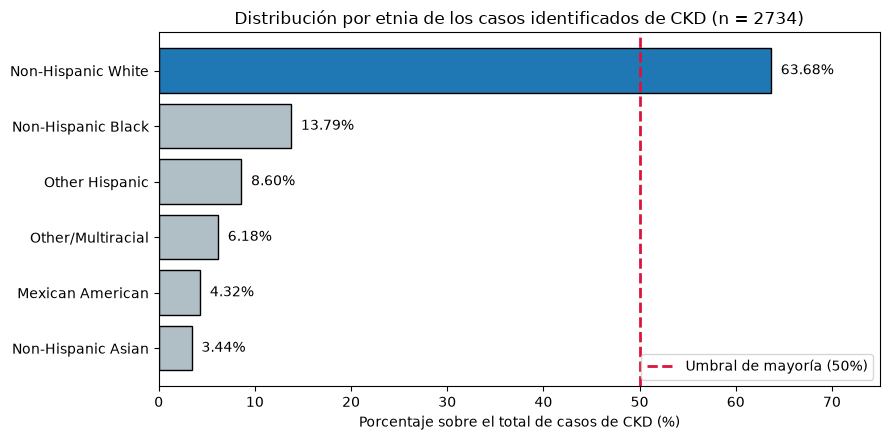

In [56]:
# filtramos los casos con CKD
df_ckd = df_limpio[df_limpio["ckd_present"] == 1].dropna(subset=["ethnicity"]).copy()

# con los datos de los de ckd, construimos la tabla de frecuencias absolutas y realtivas, con value conts contamos cuantos pacientes pertenecen a cada etinia y obtenemos las absolutas, y cuando lo normalizamos obtenemos la relativas
n_ckd = len(df_ckd)
frec_abs = df_ckd["ethnicity"].value_counts()
frec_rel = (df_ckd["ethnicity"].value_counts(normalize=True) * 100).round(2)

tabla_etnias_ckd = pd.DataFrame({
    "Frecuencia Observada": frec_abs,
    "Porcentaje (%)": frec_rel
})
print(f"Total de casos de CKD identificados: {n_ckd}\n")
display(tabla_etnias_ckd)

# 3. Aca tenemos los datos para el contraste de una proporcion, blancos no-hispanicos contra el resto, tambien calculamos la poblacion muestral observada y establecemos el umbral de mayoria en 50%
k_blancos = frec_abs["Non-Hispanic White"]
k_resto = n_ckd - k_blancos
p_hat = k_blancos / n_ckd
p_0 = 0.50  


# Aplicamps el Test Chi-cuadrado de bondad de ajuste (frecuencias observadas vs esperadas 50/50), multiplicamos la cantidad por el umbral que decidimos 50% y utilizamos ese para las esperdas
frec_obs_bin = [k_blancos, k_resto]
frec_esp_bin = [n_ckd * p_0, n_ckd * (1 - p_0)]
chi2_gof, p_valor_chi2 = stats.chisquare(f_obs=frec_obs_bin, f_exp=frec_esp_bin)

print(f"\nProporción muestral de Blancos no-hispánicos (p̂): {p_hat:.4f} ({p_hat*100:.2f}%)")
print(f"Frecuencias observadas [Blancos NH, Resto]: {frec_obs_bin} | Esperadas (50/50): {frec_esp_bin}")

print(f"Test Chi-cuadrado de bondad de ajuste: Chi2 = {chi2_gof:.4f}, p-valor = {p_valor_chi2:.4e}")


plt.figure(figsize=(9, 4.5))
colores = ["#1f77b4" if etnia == "Non-Hispanic White" else "#b0bec5" for etnia in frec_rel.index]
barras = plt.barh(frec_rel.index[::-1], frec_rel.values[::-1], color=colores[::-1], edgecolor="black")

plt.axvline(50, color="crimson", linestyle="--", linewidth=2, label="Umbral de mayoría (50%)")
plt.xlabel("Porcentaje sobre el total de casos de CKD (%)")
plt.title("Distribución por etnia de los casos identificados de CKD (n = 2734)")
plt.xlim(0, 75)

for barra in barras:
    ancho = barra.get_width()
    plt.text(ancho + 1, barra.get_y() + barra.get_height()/2, f"{ancho:.2f}%", va="center", fontsize=10)

plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

A partir del análisis realizado, se observó que el 63,68 % de los casos identificados de CKD con etnia conocida corresponde a personas blancas no hispánicas, superando el umbral del 50 % establecido para considerar una mayoría.

Para determinar si esta diferencia es estadísticamente significativa, se aplicó un test de hipótesis Chi-cuadrado de bondad de ajuste con un nivel de significancia de α = 0,05.

Dado que el p-valor obtenido es menor a 0,05, se rechaza la hipótesis nula

Por lo tanto, existe evidencia estadística suficiente para respaldar la hipótesis de investigación, concluyendo que la proporción de personas blancas no hispánicas entre los casos identificados de CKD es significativamente mayor al 50 %.